In [1]:
import pandas as pd, numpy as np
from google.colab import files
up = files.upload()          # choose startup_funding_clean.csv
df = pd.read_csv("startup_funding_clean.csv")
print(df.shape)
df[["Year","Sector","City_Std","Stage_Std","Amount_USD"]].head()

Saving startup_funding_clean.csv to startup_funding_clean.csv
(5857, 13)


,Year,Sector,City_Std,Stage_Std,Amount_USD
0,2017,Tech & SaaS,Mumbai,Private Equity,NaN
1,2017,Tech & SaaS,Bengaluru,Private Equity,12300000.0
2,2017,Real Estate,Mumbai,Private Equity,23000000.0
3,2017,Tech & SaaS,Goa,Private Equity,1000000.0
4,2017,Tech & SaaS,Gurugram,Seed/Angel,500000.0


In [2]:
d = df.dropna(subset=["Amount_USD"]).copy()      # we can't label deals with no amount
d = d[d["Amount_USD"] > 0]

d["Size_Band"] = pd.cut(d["Amount_USD"],
                        bins=[0, 1e6, 1e7, np.inf],
                        labels=["Small", "Medium", "Large"],
                        right=False)             # Small: <1M, Medium: 1M to <10M, Large: 10M+

print(len(d), "labelled deals")
print(d["Size_Band"].value_counts())
print((d["Size_Band"].value_counts(normalize=True)*100).round(1))

4332 labelled deals
Size_Band
Medium    1849
Small     1290
Large     1193
Name: count, dtype: int64
Size_Band
Medium    42.7
Small     29.8
Large     27.5
Name: proportion, dtype: float64


In [3]:
d["Sector"]    = d["Sector"].fillna("Unknown")
d["Stage_Std"] = d["Stage_Std"].fillna("Unknown")
d["City_Std"]  = d["City_Std"].fillna("Unknown")

# 167 cities is too many for the model, so keep the 10 biggest and call the rest "Other"
top_cities = d["City_Std"].value_counts().head(10).index
d["City_Group"] = np.where(d["City_Std"].isin(top_cities), d["City_Std"], "Other")

X = d[["Sector", "City_Group", "Stage_Std", "Year"]]
y = d["Size_Band"]

In [4]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)   # stratify keeps the Small/Medium/Large mix equal in both parts
print(len(X_train), "train,", len(X_test), "test")

3465 train, 867 test


In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
p = base.predict(X_test)
print("Baseline accuracy:", round(accuracy_score(y_test, p), 3))
print("Baseline macro-F1:", round(f1_score(y_test, p, average="macro"), 3))

Baseline accuracy: 0.427
Baseline macro-F1: 0.199


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

cats = ["Sector", "City_Group", "Stage_Std"]
prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cats)],
                         remainder="passthrough")      # Year passes through as a number

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                            class_weight="balanced", random_state=42),
}

fitted = {}
for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)]).fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)
    print(f"\n=== {name} ===")
    print("Accuracy:", round(accuracy_score(y_test, pred), 3),
          "| Macro-F1:", round(f1_score(y_test, pred, average="macro"), 3))
    print(classification_report(y_test, pred))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



=== Logistic Regression ===
Accuracy: 0.588 | Macro-F1: 0.59
              precision    recall  f1-score   support

       Large       0.51      0.71      0.59       239
      Medium       0.63      0.39      0.48       370
       Small       0.64      0.77      0.70       258

    accuracy                           0.59       867
   macro avg       0.59      0.62      0.59       867
weighted avg       0.60      0.59      0.58       867


=== Random Forest ===
Accuracy: 0.623 | Macro-F1: 0.626
              precision    recall  f1-score   support

       Large       0.54      0.64      0.59       239
      Medium       0.64      0.49      0.56       370
       Small       0.68      0.79      0.73       258

    accuracy                           0.62       867
   macro avg       0.62      0.64      0.63       867
weighted avg       0.63      0.62      0.62       867



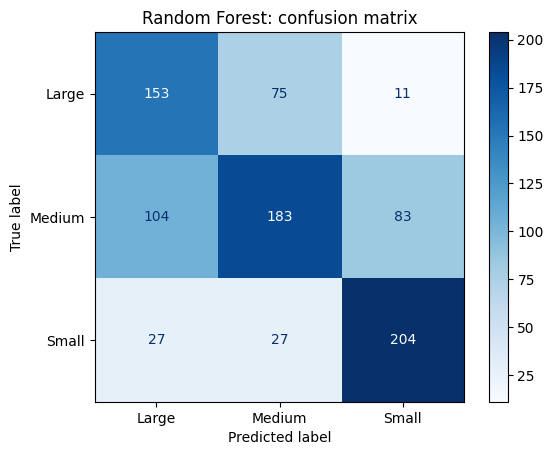

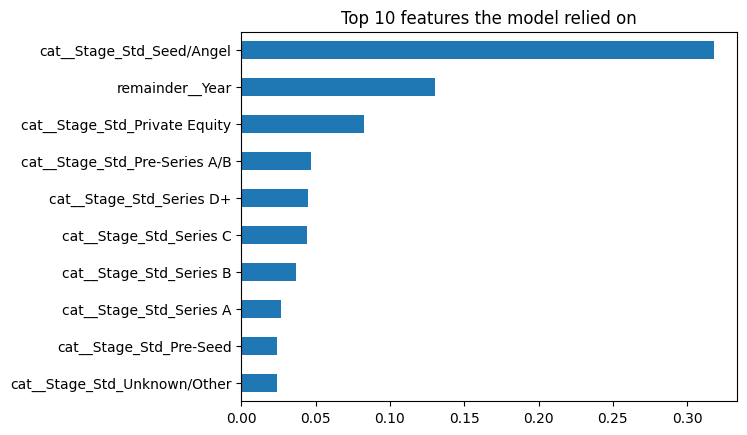

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

best = fitted["Random Forest"]
ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, cmap="Blues")
plt.title("Random Forest: confusion matrix"); plt.show()

names = best.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best.named_steps["model"].feature_importances_, index=names)
imp.sort_values(ascending=False).head(10).plot(kind="barh").invert_yaxis()
plt.title("Top 10 features the model relied on"); plt.show()

In [8]:
import joblib, json
joblib.dump(best, "deal_size_model.joblib")

options = {
    "sectors": sorted(d["Sector"].unique().tolist()),
    "cities":  sorted(d["City_Group"].unique().tolist()),
    "stages":  sorted(d["Stage_Std"].unique().tolist()),
    "year_min": int(d["Year"].min()),
    "year_max": int(d["Year"].max()),
}
json.dump(options, open("app_options.json", "w"))

files.download("deal_size_model.joblib")
files.download("app_options.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
import sklearn; print(sklearn.__version__)

1.6.1


In [11]:
import joblib, json
joblib.dump(best, "deal_size_model.joblib")

options = {
    "sectors": sorted(d["Sector"].unique().tolist()),
    "cities":  sorted(d["City_Group"].unique().tolist()),
    "stages":  sorted(d["Stage_Std"].unique().tolist()),
    "year_min": int(d["Year"].min()),
    "year_max": int(d["Year"].max()),
}
json.dump(options, open("app_options.json", "w"))

files.download("deal_size_model.joblib")
files.download("app_options.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>